In [1]:
# Cell 1: imports & config
import os, time, random
import numpy as np
import pandas as pd
from tqdm import tqdm
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True  # tolerate truncated images

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torch.amp import GradScaler, autocast

from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Config
SEQ_LEN = 8
BATCH_SIZE = 8
LR = 1e-4
EPOCHS = 20
PATIENCE = 5
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT = "liveness_checkpoint_1.pth"

# Data paths (edit these to your locations)
DATASET_PATH = r"D:\face_video"           # root where train/test folders live
FRAME_OUTPUT_PATH = os.path.join(DATASET_PATH, "frames")
CSV_PATH = os.path.join(DATASET_PATH, "real_and_fake.csv")

os.makedirs(FRAME_OUTPUT_PATH, exist_ok=True)
print("Device:", DEVICE)


Device: cuda


In [2]:
# Cell 2: extract frames from mp4 (run once if you have mp4s)
import cv2

def extract_frames(video_path, output_dir, video_id):
    cap = cv2.VideoCapture(video_path)
    frame_count = 0
    frame_paths = []
    os.makedirs(output_dir, exist_ok=True)
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break
        frame_filename = f"{video_id}_frame{frame_count:05d}.jpg"
        frame_path = os.path.join(output_dir, frame_filename)
        # write as jpg (converted BGR->RGB automatically by cv2.imwrite)
        cv2.imwrite(frame_path, frame)
        frame_paths.append(frame_path.replace("\\", "/"))
        frame_count += 1
    cap.release()
    return frame_paths

# Example usage: walk through train/test folders and extract frames
# Directory structure expected:
# DATASET_PATH/
#   train/
#     real_video/
#     attack/
#   test/
#     real_video/
#     attack/
#
# This will create frame images into FRAME_OUTPUT_PATH and build CSV.

if not os.path.exists(CSV_PATH):
    data = []
    for split in ["train", "test"]:
        split_path = os.path.join(DATASET_PATH, split)
        if not os.path.exists(split_path):
            continue
        for label_dir in os.listdir(split_path):
            label_path = os.path.join(split_path, label_dir)  # e.g. real_video or attack
            if not os.path.isdir(label_path):
                continue
            for file in tqdm(os.listdir(label_path), desc=f"Processing {label_dir} in {split}"):
                if file.lower().endswith(".mp4"):
                    video_id = f"{split}_{label_dir}_{os.path.splitext(file)[0]}"
                    video_path = os.path.join(label_path, file)
                    fpaths = extract_frames(video_path, FRAME_OUTPUT_PATH, video_id)
                    # record frames
                    for fp in fpaths:
                        data.append({"video_id": video_id, "frame_path": fp,
                                     "label": "real" if "real" in label_dir.lower() else "attack",
                                     "split": split})
    df = pd.DataFrame(data)
    df.to_csv(CSV_PATH, index=False)
    print("CSV created:", CSV_PATH)
else:
    print("CSV exists, skipping extraction.")


CSV exists, skipping extraction.


In [3]:
# Cell 3: load CSV and preview
df = pd.read_csv(CSV_PATH)
print("Total frames:", len(df))
print("Unique videos:", df["video_id"].nunique())
print(df.head())


Total frames: 56570
Unique videos: 80
   video_id                         frame_path label
0         0  D:/face_video/frames/0_frame0.jpg  real
1         0  D:/face_video/frames/0_frame1.jpg  real
2         0  D:/face_video/frames/0_frame2.jpg  real
3         0  D:/face_video/frames/0_frame3.jpg  real
4         0  D:/face_video/frames/0_frame4.jpg  real


In [4]:
# Cell 4: transforms and VideoDataset
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

class VideoDataset(Dataset):
    def __init__(self, df, seq_len=SEQ_LEN, transform=None):
        self.df = df.copy().reset_index(drop=True)
        self.seq_len = seq_len
        self.transform = transform

        # auto-build label map (robust)
        unique_labels = sorted(self.df["label"].unique())
        self.label_map = {lab: idx for idx, lab in enumerate(unique_labels)}
        print("Label mapping:", self.label_map)

        # group frames by video_id
        grouped = self.df.groupby("video_id")["frame_path"].apply(list)
        self.videos = grouped.to_dict()
        labels = self.df.groupby("video_id")["label"].first().to_dict()
        self.labels = labels
        self.video_ids = list(self.videos.keys())

    def __len__(self):
        return len(self.video_ids)

    def __getitem__(self, idx):
        vid = self.video_ids[idx]
        frames = self.videos[vid]
        raw_label = self.labels[vid]
        label = self.label_map[raw_label]

        # sample frames
        if len(frames) >= self.seq_len:
            idxs = np.linspace(0, len(frames) - 1, self.seq_len, dtype=int)
        else:
            idxs = np.random.choice(len(frames), self.seq_len, replace=True)

        selected = [frames[i] for i in idxs]
        imgs = []
        for fp in selected:
            try:
                img = Image.open(fp).convert("RGB")
                if self.transform:
                    img = self.transform(img)
                imgs.append(img)
            except Exception as e:
                # if a frame is corrupted, replace with a zero tensor of same shape
                # (this lets training continue)
                print("Warning: failed to open", fp, "->", e)
                dummy = torch.zeros(3, 128, 128)  # match transform size
                imgs.append(dummy)

        imgs = torch.stack(imgs)      # shape: (T, C, H, W)
        imgs = imgs.permute(1, 0, 2, 3) if False else imgs  # keep (T,C,H,W) for clarity
        # convert to (C, T, H, W) not needed — model expects (B,T,C,H,W)
        # return as (T, C, H, W); training collate will produce (B, T, C, H, W)
        return imgs, torch.tensor(label, dtype=torch.long)


In [5]:
# Cell 5: model definition
class CNN_LSTM(nn.Module):
    def __init__(self, hidden_size=128, num_classes=None):
        super().__init__()
        base = models.mobilenet_v2(weights="IMAGENET1K_V1")
        self.feature_extractor = base.features  # returns (B, feat_dim, H', W')
        self.pool = nn.AdaptiveAvgPool2d((1,1))
        feat_dim = base.last_channel

        self.lstm = nn.LSTM(input_size=feat_dim, hidden_size=hidden_size, num_layers=1, batch_first=True)
        # if num_classes is None, we will infer later
        self.fc = None
        self._feat_dim = feat_dim
        self._hidden_size = hidden_size
        self._num_classes = num_classes

    def set_num_classes(self, n):
        self._num_classes = n
        self.fc = nn.Linear(self._hidden_size, self._num_classes)

    def forward(self, x):
        # x shape: (B, T, C, H, W)
        B, T, C, H, W = x.shape
        x = x.view(B*T, C, H, W)
        feats = self.feature_extractor(x)            # (B*T, feat_dim, h, w)
        feats = self.pool(feats).view(B, T, -1)      # (B, T, feat_dim)
        out, _ = self.lstm(feats)                    # (B, T, hidden)
        out = self.fc(out[:, -1, :])                 # (B, num_classes)
        return out


In [6]:
# Cell 6: prepare dataloaders
# shuffle videos, split 80/20 by videos
vids = df["video_id"].unique().tolist()
random.seed(42)
random.shuffle(vids)
split_idx = int(0.8 * len(vids))
train_vids, test_vids = vids[:split_idx], vids[split_idx:]

train_df = df[df["video_id"].isin(train_vids)].reset_index(drop=True)
test_df = df[df["video_id"].isin(test_vids)].reset_index(drop=True)

train_ds = VideoDataset(train_df, seq_len=SEQ_LEN, transform=transform)
test_ds  = VideoDataset(test_df,  seq_len=SEQ_LEN, transform=transform)

# set num_workers based on your CPU: 0 for Windows debugging, 4+ for linux
NUM_WORKERS = 4 if os.name != "nt" else 0

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)

print("Train videos:", len(train_ds), "Test videos:", len(test_ds))
print("Batches per epoch (train):", len(train_loader))


Label mapping: {'attack': 0, 'real': 1}
Label mapping: {'attack': 0, 'real': 1}
Train videos: 64 Test videos: 16
Batches per epoch (train): 8


In [7]:
# Cell 7: training loop
def train_model(model, train_loader, val_loader, optimizer, criterion, scaler,
                epochs=EPOCHS, patience=PATIENCE, checkpoint_path=CHECKPOINT):
    model.to(DEVICE)
    best_val_loss = float("inf")
    patience_counter = 0
    start_epoch = 0

    history = {"train_loss":[], "val_loss":[], "train_acc":[], "val_acc":[]}

    # resume if checkpoint exists
    if os.path.exists(checkpoint_path):
        ckpt = torch.load(checkpoint_path, map_location=DEVICE)
        model.load_state_dict(ckpt["model"])
        optimizer.load_state_dict(ckpt["optimizer"])
        start_epoch = ckpt.get("epoch", 0) + 1
        print("Resumed from epoch", start_epoch)

    for epoch in range(start_epoch, epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0
        pbar = tqdm(train_loader, desc=f"[TRAIN] Epoch {epoch+1}/{epochs}", leave=False)
        for imgs, labels in pbar:
            # imgs: (B, T, C, H, W) because dataset returned (T,C,H,W) and collate made B dim
            # ensure shape is (B, T, C, H, W)
            if imgs.ndim == 4:
                # if accidentally collapsed, skip
                continue
            imgs = imgs.to(DEVICE, non_blocking=True).float()
            labels = labels.to(DEVICE, non_blocking=True)
            optimizer.zero_grad()

            with autocast(device_type="cuda" if DEVICE.type=="cuda" else "cpu"):
                outputs = model(imgs)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * labels.size(0)
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

            pbar.set_postfix(loss=loss.item(), acc=correct/total)

        train_loss = running_loss / total if total>0 else 0
        train_acc = correct / total if total>0 else 0

        # validation
        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total = 0
        with torch.no_grad():
            for imgs, labels in tqdm(val_loader, desc="[VAL]", leave=False):
                imgs = imgs.to(DEVICE, non_blocking=True).float()
                labels = labels.to(DEVICE, non_blocking=True)
                outputs = model(imgs)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * labels.size(0)
                _, preds = torch.max(outputs, 1)
                val_correct += (preds == labels).sum().item()
                val_total += labels.size(0)

        val_loss = val_loss / val_total if val_total>0 else 0
        val_acc = val_correct / val_total if val_total>0 else 0

        print(f"Epoch {epoch+1}: Train Loss {train_loss:.4f}, Acc {train_acc:.4f} | "
              f"Val Loss {val_loss:.4f}, Acc {val_acc:.4f}")

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        # checkpointing
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save({"model": model.state_dict(),
                        "optimizer": optimizer.state_dict(),
                        "epoch": epoch}, checkpoint_path)
            print("Checkpoint saved.")
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print("Early stopping triggered.")
                break

    return model, history


In [10]:
# Cell 8: instantiate model and run
model = CNN_LSTM(hidden_size=128)  # create model
# set number of classes according to dataset label map
# we can infer from dataset:
num_classes = len(train_ds.label_map)
model.set_num_classes(num_classes)
model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scaler = GradScaler("cuda")

model, history = train_model(model, train_loader, test_loader, optimizer, criterion, scaler,
                             epochs=EPOCHS, patience=PATIENCE, checkpoint_path=CHECKPOINT)


Epoch 1: Train Loss 0.4134, Acc 0.9375 | Val Loss 0.1993, Acc 1.0000
Checkpoint saved.


Epoch 2: Train Loss 0.1171, Acc 1.0000 | Val Loss 0.0697, Acc 1.0000
Checkpoint saved.


Epoch 3: Train Loss 0.0498, Acc 1.0000 | Val Loss 0.0383, Acc 1.0000
Checkpoint saved.


Epoch 4: Train Loss 0.0261, Acc 1.0000 | Val Loss 0.0255, Acc 1.0000
Checkpoint saved.


Epoch 5: Train Loss 0.0175, Acc 1.0000 | Val Loss 0.0202, Acc 1.0000
Checkpoint saved.


...

Epoch 16: Train Loss 0.0039, Acc 1.0000 | Val Loss 0.0064, Acc 1.0000
Checkpoint saved.


Epoch 17: Train Loss 0.0036, Acc 1.0000 | Val Loss 0.0055, Acc 1.0000
Checkpoint saved.


Epoch 18: Train Loss 0.0034, Acc 1.0000 | Val Loss 0.0055, Acc 1.0000
Checkpoint saved.


Epoch 19: Train Loss 0.0032, Acc 1.0000 | Val Loss 0.0053, Acc 1.0000
Checkpoint saved.


Epoch 20: Train Loss 0.0030, Acc 1.0000 | Val Loss 0.0057, Acc 1.0000


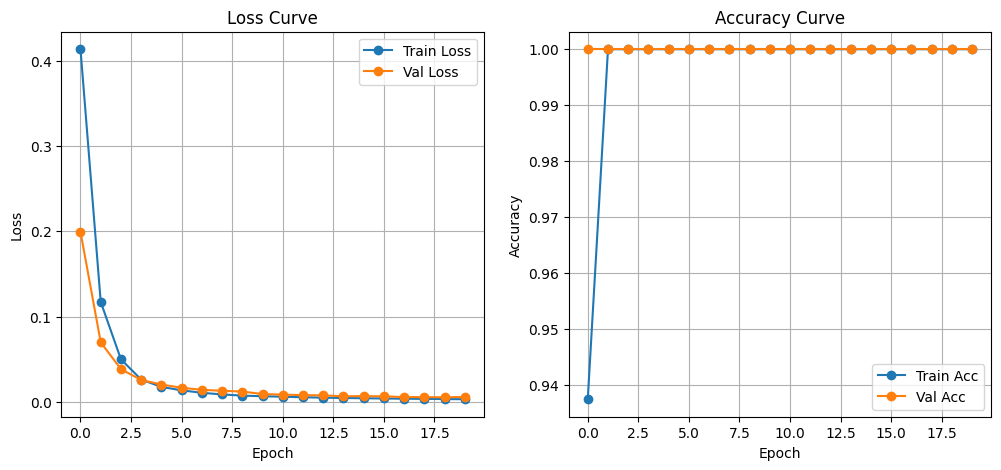

In [11]:
# Cell 9: plot
train_loss = history["train_loss"]
val_loss = history["val_loss"]
train_acc = history["train_acc"]
val_acc = history["val_acc"]

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(train_loss, "-o", label="Train Loss")
plt.plot(val_loss, "-o", label="Val Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.title("Loss Curve"); plt.grid(True)

plt.subplot(1,2,2)
plt.plot(train_acc, "-o", label="Train Acc")
plt.plot(val_acc, "-o", label="Val Acc")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.title("Accuracy Curve"); plt.grid(True)

plt.show()


Evaluating: 100%|██████████| 2/2 [00:02<00:00,  1.32s/it]

              precision    recall  f1-score   support

        real       1.00      1.00      1.00        16

    accuracy                           1.00        16
   macro avg       1.00      1.00      1.00        16
weighted avg       1.00      1.00      1.00        16




C:\Users\user\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\metrics\_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


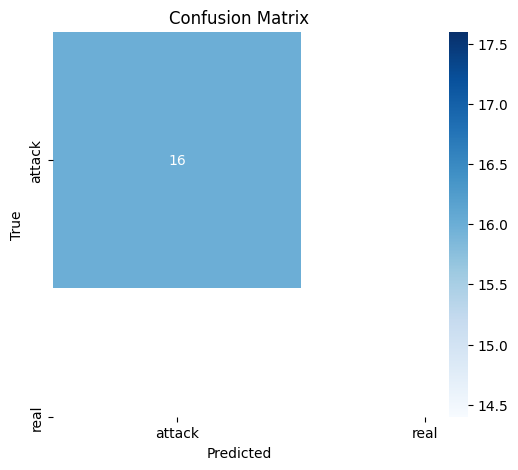

In [14]:
# Cell 10: evaluate on test set (uses test_loader)
y_true, y_pred = [], []
model.eval()
with torch.no_grad():
    for imgs, labels in tqdm(test_loader, desc="Evaluating"):
        imgs = imgs.to(DEVICE).float()
        labels = labels.to(DEVICE)
        outputs = model(imgs)
        _, preds = torch.max(outputs, 1)
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

# Dynamically determine the unique classes in y_true
unique_classes = sorted(set(y_true))
target_names = [name for name, idx in train_ds.label_map.items() if idx in unique_classes]

print(classification_report(y_true, y_pred, target_names=target_names))
cm = confusion_matrix(y_true, y_pred, labels=unique_classes)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=list(train_ds.label_map.keys()),
            yticklabels=list(train_ds.label_map.keys()), cmap="Blues")
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion Matrix"); plt.show()


📊 CNN+LSTM Model Results
              precision    recall  f1-score   support

        real       1.00      1.00      1.00        16

    accuracy                           1.00        16
   macro avg       1.00      1.00      1.00        16
weighted avg       1.00      1.00      1.00        16



C:\Users\user\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\metrics\_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


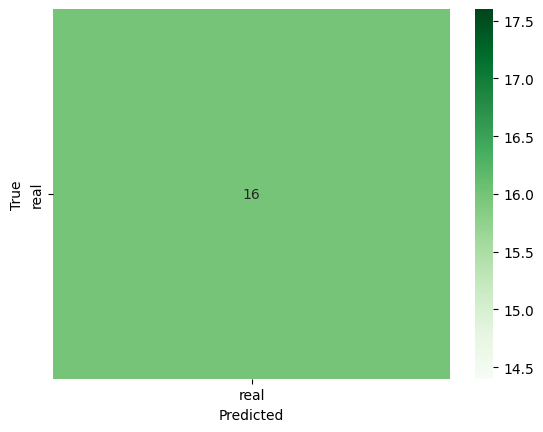

In [28]:
# Cell 5: model definition
class CNN_LSTM(nn.Module):
    def __init__(self, hidden_size=128, num_classes=None):
        super().__init__()
        base = models.mobilenet_v2(weights="IMAGENET1K_V1")
        self.feature_extractor = base.features  # returns (B, feat_dim, H', W')
        self.pool = nn.AdaptiveAvgPool2d((1,1))
        feat_dim = base.last_channel

        self.lstm = nn.LSTM(input_size=feat_dim, hidden_size=hidden_size, num_layers=1, batch_first=True)
        # if num_classes is None, we will infer later
        self.fc = None
        self._feat_dim = feat_dim
        self._hidden_size = hidden_size
        self._num_classes = num_classes

    def set_num_classes(self, n):
        self._num_classes = n
        self.fc = nn.Linear(self._hidden_size, self._num_classes)

    def forward(self, x):
        # x shape: (B, T, C, H, W)
        B, T, C, H, W = x.shape
        x = x.view(B*T, C, H, W)
        feats = self.feature_extractor(x)            # (B*T, feat_dim, h, w)
        feats = self.pool(feats).view(B, T, -1)      # (B, T, feat_dim)
        out, _ = self.lstm(feats)                    # (B, T, hidden)
        out = self.fc(out[:, -1, :])                 # (B, num_classes)
        return out


# --- Load CNN+LSTM ---
# Adjust hidden_dim to match the checkpoint (512 in this case)
lstm_model = CNN_LSTM(hidden_size=128)
# Set the number of classes before loading the checkpoint
lstm_model.set_num_classes(2)
# Load the checkpoint and extract the model's state_dict
checkpoint = torch.load("liveness_checkpoint_1.pth", map_location=DEVICE)
lstm_model.load_state_dict(checkpoint["model"])
lstm_model.to(DEVICE)
lstm_model.eval()

# --- Evaluate ---
all_labels, all_preds = [], []

with torch.no_grad():
    for inputs, labels in test_loader:  # <- use your test_loader for videos (shape: [batch, seq_len, C, H, W])
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
        outputs = lstm_model(inputs)
        _, preds = torch.max(outputs, 1)
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

print("📊 CNN+LSTM Model Results")
# Dynamically determine the unique classes in y_true
unique_classes = sorted(set(all_labels))
target_names = [name for name, idx in train_ds.label_map.items() if idx in unique_classes]

print(classification_report(all_labels, all_preds, target_names=target_names))

# --- Confusion Matrix ---
cm = confusion_matrix(all_labels, all_preds, labels=unique_classes)
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=target_names,
            yticklabels=target_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


In [31]:
from sklearn.metrics import confusion_matrix

def calculate_spoof_metrics(y_true, y_pred):
    # Labels: 0 = Real, 1 = Attack
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])  # Ensure both classes are included
    if cm.shape != (2, 2):  # Handle cases where confusion matrix is not 2x2
        raise ValueError("Confusion matrix must be 2x2. Check if both classes (0 and 1) are present in y_true and y_pred.")
    tn, fp, fn, tp = cm.ravel()

    # BPCER: Real misclassified as Fake
    BPCER = fn / (tn + fn + 1e-6)

    # APCER: Fake misclassified as Real
    APCER = fp / (fp + tp + 1e-6)

    # ACER
    ACER = (APCER + BPCER) / 2

    return {
        "APCER": round(APCER*100, 2),
        "BPCER": round(BPCER*100, 2),
        "ACER": round(ACER*100, 2)
    }

# Example usage:
results = calculate_spoof_metrics(all_labels, all_preds)
print("📊 Anti-Spoofing Metrics:", results)


📊 Anti-Spoofing Metrics: {'APCER': np.float64(0.0), 'BPCER': np.float64(0.0), 'ACER': np.float64(0.0)}
